In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_wine
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [ ]:
#Load dataset and split training/testing data
data = load_wine(as_frame=True)

df = data.frame
df = df[df["target"] < 2]

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", X.shape[1])
print("Classes:", list(data.target_names[:2]))

Training samples: 104
Testing samples: 26
Features: 13
Classes: [np.str_('class_0'), np.str_('class_1')]


In [ ]:
#Create Bagging and Boosting models
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    )
}

In [ ]:
#Train models and compare performance
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predicted_classes = model.predict(X_test)
    predicted_probabilities = model.predict_proba(X_test)[:, 1]

    predictions[name] = predicted_classes

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted_classes),
        "F1 Score": f1_score(y_test, predicted_classes),
        "ROC-AUC": roc_auc_score(y_test, predicted_probabilities)
    })

results_table = pd.DataFrame(results).set_index("Model")

print(results_table.round(4))

               Accuracy  F1 Score  ROC-AUC
Model                                     
Bagging          1.0000     1.000      1.0
Random Forest    1.0000     1.000      1.0
AdaBoost         0.9615     0.963      1.0


In [ ]:
#Compare component learners and learning strategies
model_summary = pd.DataFrame(
    {
        "Component learners": [
            len(models["Bagging"].estimators_),
            len(models["Random Forest"].estimators_),
            len(models["AdaBoost"].estimators_)
        ],

        "Learning strategy": [
            "Independent bootstrap trees",
            "Bootstrap trees + random features",
            "Sequential weighted weak learners"
        ]
    },
    index=models.keys()
)

print(model_summary)

               Component learners                  Learning strategy
Bagging                       100        Independent bootstrap trees
Random Forest                 100  Bootstrap trees + random features
AdaBoost                      100  Sequential weighted weak learners


In [ ]:
#Detailed evaluation of Random Forest
print(
    classification_report(
        y_test,
        predictions["Random Forest"],
        target_names=data.target_names[:2]
    )
)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       1.00      1.00      1.00        14

    accuracy                           1.00        26
   macro avg       1.00      1.00      1.00        26
weighted avg       1.00      1.00      1.00        26



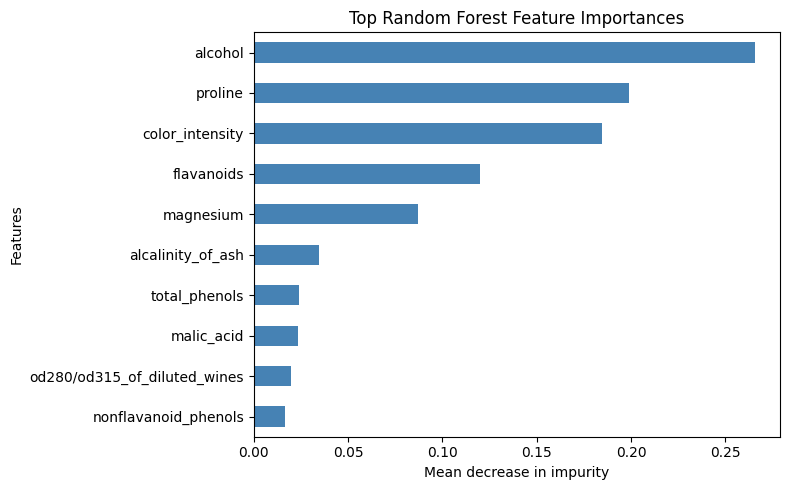

In [ ]:
#Visualize Random Forest feature importance
importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X.columns
).sort_values(ascending=False).head(10).sort_values()

importance.plot(
    kind="barh",
    figsize=(8, 5),
    color="steelblue"
)

plt.xlabel("Mean decrease in impurity")
plt.ylabel("Features")
plt.title("Top Random Forest Feature Importances")
plt.tight_layout()
plt.show()

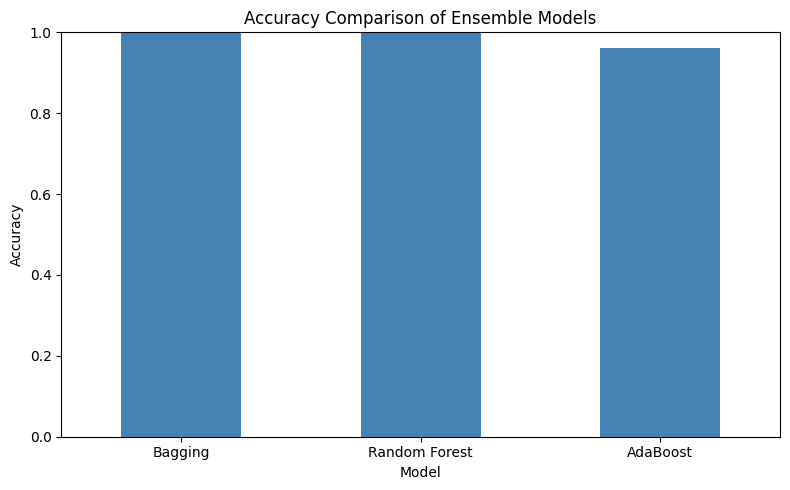

In [ ]:
#Visualize model accuracy
results_table["Accuracy"].plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    color="steelblue"
)

plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Ensemble Models")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()